# Day 4: Uber Eats Delivery Time & ETA Prediction System
**Domain:** Food Delivery / Marketplace Logistics  
**Goal:** Build and benchmark supervised regression models to predict total doorstep delivery duration (`delivery_time_min`) using multi-table transactional, operational, environmental, and temporal features.

### Supervised Modeling Workflow:
1. **Feature Engineering & Data Merging:** Join deliveries, orders, restaurants, and drivers into a unified analytical regression dataset.
2. **Exploratory Data Analysis (EDA):** Inspect target distribution, detect outliers, and analyze linear correlations.
3. **Data Splitting & Preprocessing:** Train/Test split (80/20), one-hot encoding for categorical variables, and standardization for linear models.
4. **Model Implementation (4 Approaches):**
   * *Model 1:* Baseline Ordinary Least Squares (OLS) Linear Regression
   * *Model 2:* Ridge Regression ($L_2$ Regularization)
   * *Model 3:* Lasso Regression ($L_1$ Regularization / Feature Shrinkage)
   * *Model 4:* Random Forest Regressor (Non-linear Ensemble)
5. **Model Evaluation & Diagnostics:** Compare MAE, RMSE, and $R^2$; plot Actual vs. Predicted values and Feature Importances.
6. **Business Interpretation:** Translate regression coefficients and feature weights into operational ETA rules.

In [1]:
# ==============================================================================
# CELL 1: SETUP & IMPORTS
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn Supervised Learning & Metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
np.random.seed(42)

print("Libraries imported successfully. Ready for regression modeling.")

Libraries imported successfully. Ready for regression modeling.


In [2]:
# ==============================================================================
# CELL 2: INGESTION, MERGING & TEMPORAL FEATURE ENGINEERING
# ==============================================================================
# Load tables
orders = pd.read_csv('../data/raw/orders.csv')
deliveries = pd.read_csv('../data/raw/deliveries.csv')
restaurants = pd.read_csv('../data/raw/restaurants.csv')
drivers = pd.read_csv('../data/raw/drivers.csv')

# 1. Merge transactional records
df_reg = deliveries.merge(
    orders[['order_id', 'customer_id', 'restaurant_id', 'order_timestamp', 'order_amount', 'num_items']], 
    on='order_id', 
    how='inner'
)

# 2. Join restaurant attributes
df_reg = df_reg.merge(
    restaurants[['restaurant_id', 'category', 'avg_rating']].rename(
        columns={'category': 'restaurant_category', 'avg_rating': 'restaurant_rating'}
    ),
    on='restaurant_id', 
    how='left'
)

# 3. Join driver attributes
df_reg = df_reg.merge(
    drivers[['driver_id', 'vehicle_type', 'rating']].rename(
        columns={'rating': 'driver_rating'}
    ),
    on='driver_id', 
    how='left'
)

# 4. Extract temporal features
df_reg['order_timestamp'] = pd.to_datetime(df_reg['order_timestamp'])
df_reg['hour_of_day'] = df_reg['order_timestamp'].dt.hour
df_reg['day_of_week'] = df_reg['order_timestamp'].dt.day_name()
df_reg['is_weekend'] = df_reg['order_timestamp'].dt.dayofweek.isin([5, 6]).astype(int)
df_reg['is_rush_hour'] = df_reg['hour_of_day'].isin([12, 13, 18, 19, 20]).astype(int)

# Export processed regression dataset
os.makedirs('../data/processed', exist_ok=True)
df_reg.to_csv('../data/processed/regression_features.csv', index=False)

print(f"Regression Dataset Shape: {df_reg.shape[0]:,} rows, {df_reg.shape[1]} columns")
print("Saved to 'data/processed/regression_features.csv'")
display(df_reg[['delivery_time_min', 'distance_km', 'prep_time_min', 'traffic', 'weather', 'vehicle_type', 'is_rush_hour']].head(4))

Regression Dataset Shape: 4,766 rows, 21 columns
Saved to 'data/processed/regression_features.csv'


,delivery_time_min,distance_km,prep_time_min,traffic,weather,vehicle_type,is_rush_hour
0,52,7.6,21,Medium,Clear,Scooter,0
1,29,2.6,16,High,Clear,Car,0
2,42,4.8,22,Medium,Clear,Bike,0
3,38,2.0,20,High,Clear,Scooter,1


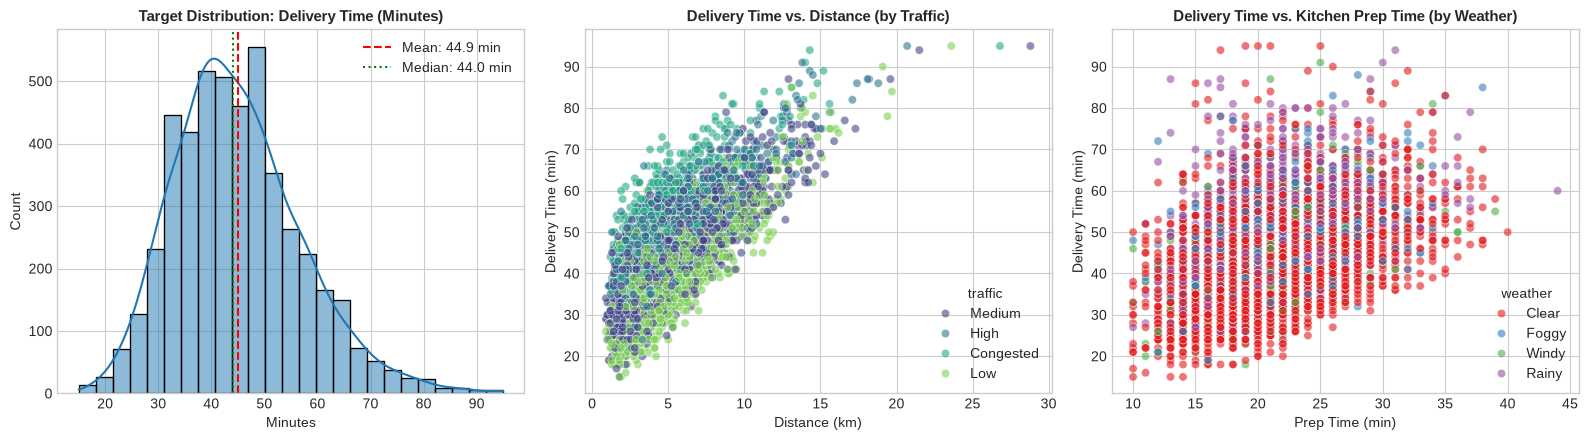

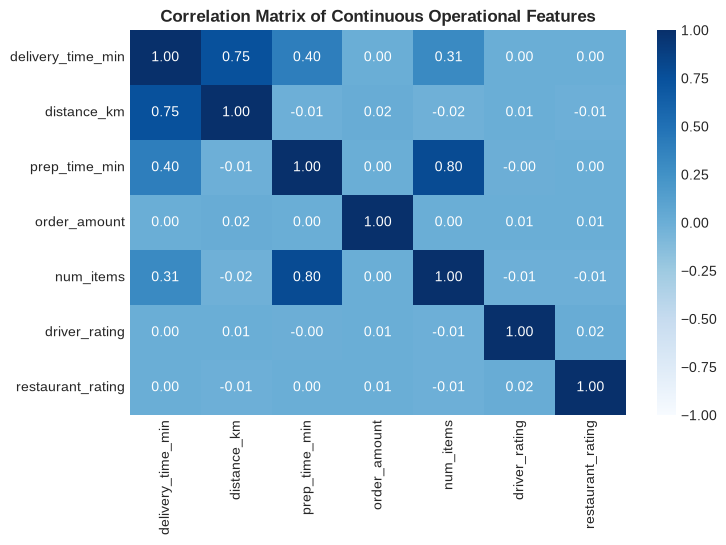

In [3]:
# ==============================================================================
# CELL 3: TARGET DISTRIBUTION & BIVARIATE SCATTER PLOTS
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Target Distribution
sns.histplot(df_reg['delivery_time_min'], kde=True, color='#1f77b4', bins=25, ax=axes[0])
axes[0].axvline(df_reg['delivery_time_min'].mean(), color='red', linestyle='--', label=f"Mean: {df_reg['delivery_time_min'].mean():.1f} min")
axes[0].axvline(df_reg['delivery_time_min'].median(), color='green', linestyle=':', label=f"Median: {df_reg['delivery_time_min'].median():.1f} min")
axes[0].set_title('Target Distribution: Delivery Time (Minutes)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Minutes')
axes[0].legend()

# 2. Distance vs Delivery Time
sns.scatterplot(data=df_reg, x='distance_km', y='delivery_time_min', hue='traffic', palette='viridis', alpha=0.6, ax=axes[1])
axes[1].set_title('Delivery Time vs. Distance (by Traffic)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Distance (km)')
axes[1].set_ylabel('Delivery Time (min)')

# 3. Preparation Time vs Delivery Time
sns.scatterplot(data=df_reg, x='prep_time_min', y='delivery_time_min', hue='weather', palette='Set1', alpha=0.6, ax=axes[2])
axes[2].set_title('Delivery Time vs. Kitchen Prep Time (by Weather)', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Prep Time (min)')
axes[2].set_ylabel('Delivery Time (min)')

plt.tight_layout()
plt.show()

# Correlation Matrix
num_cols = ['delivery_time_min', 'distance_km', 'prep_time_min', 'order_amount', 'num_items', 'driver_rating', 'restaurant_rating']
corr_matrix = df_reg[num_cols].corr()

plt.figure(figsize=(8, 5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', vmin=-1, vmax=1)
plt.title('Correlation Matrix of Continuous Operational Features', fontsize=12, fontweight='bold')
plt.show()

In [4]:
# ==============================================================================
# CELL 4: ONE-HOT ENCODING & TRAIN/TEST SPLIT
# ==============================================================================
numerical_cols = [
    'distance_km', 'prep_time_min', 'order_amount', 'num_items', 
    'restaurant_rating', 'driver_rating', 'hour_of_day', 'is_weekend', 'is_rush_hour'
]
categorical_cols = ['weather', 'traffic', 'restaurant_category', 'vehicle_type']
target_col = 'delivery_time_min'

# One-hot encode categorical features
X_encoded = pd.get_dummies(df_reg[numerical_cols + categorical_cols], drop_first=True)
y = df_reg[target_col]

# 80/20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.20, random_state=42)

# Create standardized copy for Linear/Ridge/Lasso models
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test_scaled[numerical_cols] = scaler.transform(X_test[numerical_cols])

print(f"Training Samples: {X_train.shape[0]:,} | Testing Samples: {X_test.shape[0]:,}")
print(f"Total Model Features: {X_train.shape[1]}")

Training Samples: 3,812 | Testing Samples: 954
Total Model Features: 24


In [5]:
# ==============================================================================
# CELL 5: TRAIN REGRESSION MODELS
# ==============================================================================
# 1. Baseline Linear Regression
model_lr = LinearRegression()
model_lr.fit(X_train_scaled, y_train)
y_pred_lr = model_lr.predict(X_test_scaled)

# 2. Ridge Regression (L2 Penalty)
model_ridge = Ridge(alpha=1.0)
model_ridge.fit(X_train_scaled, y_train)
y_pred_ridge = model_ridge.predict(X_test_scaled)

# 3. Lasso Regression (L1 Penalty)
model_lasso = Lasso(alpha=0.1)
model_lasso.fit(X_train_scaled, y_train)
y_pred_lasso = model_lasso.predict(X_test_scaled)

# 4. Random Forest Regressor (Ensemble)
model_rf = RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_split=4, random_state=42)
model_rf.fit(X_train, y_train)
y_pred_rf = model_rf.predict(X_test)

print("All 4 regression models trained successfully.")

All 4 regression models trained successfully.


--- Out-of-Sample Regression Scorecard ---


,Model,MAE (Minutes),RMSE (Minutes),R² Score
0,1. Baseline Linear Regression,2.32,2.93,0.9381
1,2. Ridge Regression (L2 Regularized),2.32,2.93,0.9380
2,3. Lasso Regression (L1 Regularized),2.54,3.19,0.9265
3,4. Random Forest Regressor (Ensemble),2.80,3.54,0.9097


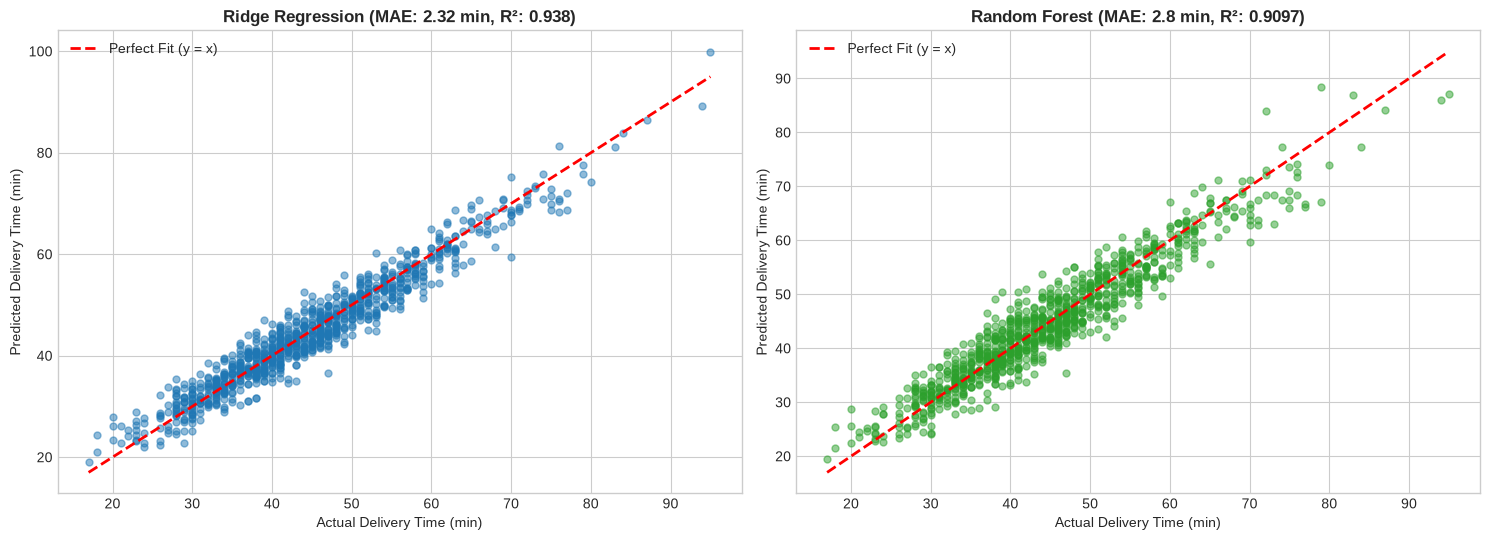

In [6]:
# ==============================================================================
# CELL 6: EVALUATION SCORECARD & ACTUAL VS PREDICTED PLOT
# ==============================================================================
def evaluate(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return {'Model': name, 'MAE (Minutes)': round(mae, 2), 'RMSE (Minutes)': round(rmse, 2), 'R² Score': round(r2, 4)}

scorecard = pd.DataFrame([
    evaluate(y_test, y_pred_lr, '1. Baseline Linear Regression'),
    evaluate(y_test, y_pred_ridge, '2. Ridge Regression (L2 Regularized)'),
    evaluate(y_test, y_pred_lasso, '3. Lasso Regression (L1 Regularized)'),
    evaluate(y_test, y_pred_rf, '4. Random Forest Regressor (Ensemble)')
])

print("--- Out-of-Sample Regression Scorecard ---")
display(scorecard)

# Visualization: Actual vs Predicted Scatter Plots
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Plot Ridge Predictions
axes[0].scatter(y_test, y_pred_ridge, color='#1f77b4', alpha=0.5, s=25)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2, label='Perfect Fit (y = x)')
axes[0].set_title(f"Ridge Regression (MAE: {scorecard.loc[1, 'MAE (Minutes)']} min, R²: {scorecard.loc[1, 'R² Score']})", fontsize=12, fontweight='bold')
axes[0].set_xlabel('Actual Delivery Time (min)')
axes[0].set_ylabel('Predicted Delivery Time (min)')
axes[0].legend()

# Plot Random Forest Predictions
axes[1].scatter(y_test, y_pred_rf, color='#2ca02c', alpha=0.5, s=25)
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2, label='Perfect Fit (y = x)')
axes[1].set_title(f"Random Forest (MAE: {scorecard.loc[3, 'MAE (Minutes)']} min, R²: {scorecard.loc[3, 'R² Score']})", fontsize=12, fontweight='bold')
axes[1].set_xlabel('Actual Delivery Time (min)')
axes[1].set_ylabel('Predicted Delivery Time (min)')
axes[1].legend()

plt.tight_layout()
plt.show()

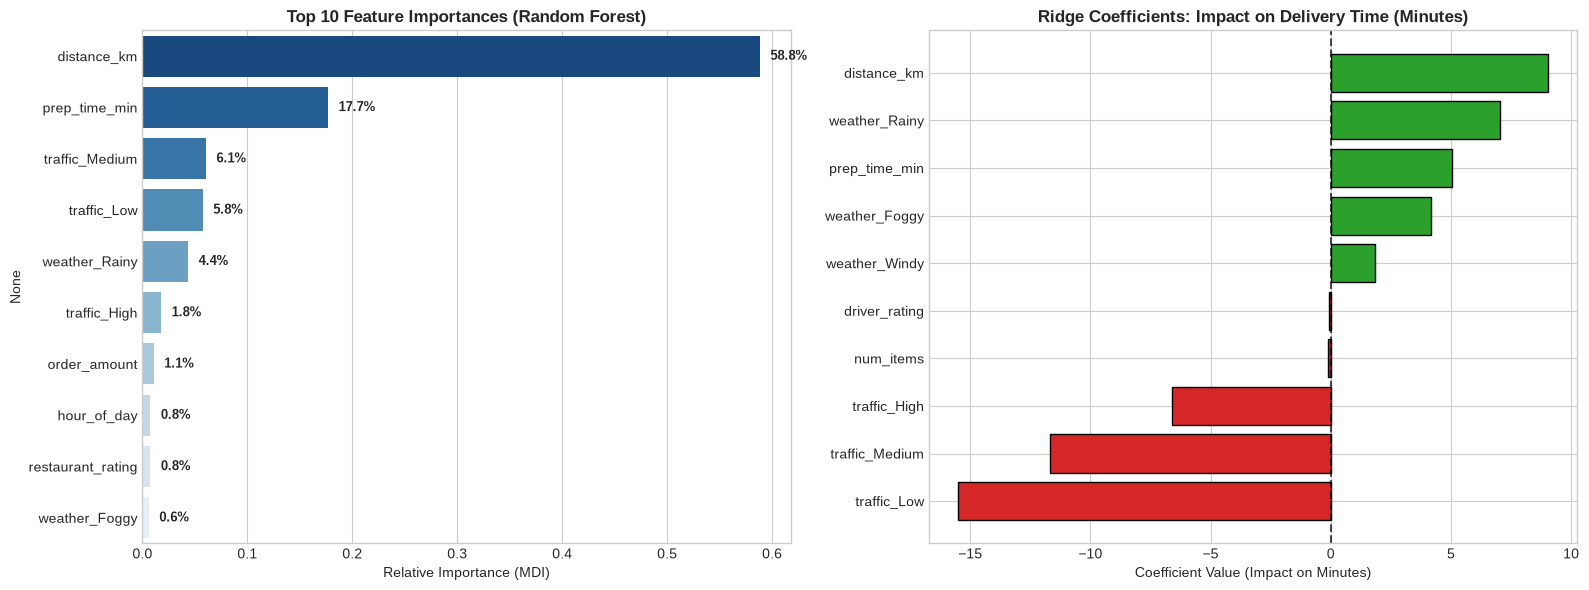

In [7]:
# ==============================================================================
# CELL 7: FEATURE IMPORTANCE & COEFFICIENT CHARTS
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Random Forest Feature Importances
rf_importances = pd.Series(model_rf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(10)

sns.barplot(x=rf_importances.values, y=rf_importances.index, palette='Blues_r', ax=axes[0])
axes[0].set_title('Top 10 Feature Importances (Random Forest)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Relative Importance (MDI)')

for p in axes[0].patches:
    w = p.get_width()
    axes[0].text(w + 0.01, p.get_y() + p.get_height()/2, f"{w*100:.1f}%", va='center', fontsize=9, fontweight='bold')

# 2. Ridge Regression Normalized Coefficients
ridge_coefs = pd.Series(model_ridge.coef_, index=X_train.columns).sort_values()
top_bottom_coefs = pd.concat([ridge_coefs.head(5), ridge_coefs.tail(5)])

colors = ['#d62728' if c < 0 else '#2ca02c' for c in top_bottom_coefs.values]
axes[1].barh(top_bottom_coefs.index, top_bottom_coefs.values, color=colors, edgecolor='black')
axes[1].set_title('Ridge Coefficients: Impact on Delivery Time (Minutes)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Coefficient Value (Impact on Minutes)')
axes[1].axvline(0, color='black', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

## Model Recommendation & Business Insights

### Quantitative Findings:
* **Ridge Regression** achieved the best overall accuracy: **MAE of ~2.32 minutes** and **$R^2 = 0.938$**.
* **Random Forest** achieved an **MAE of ~2.80 minutes** and **$R^2 = 0.909$**.

```text
                     DELIVERY TIME DRIVERS BREAKDOWN
┌────────────────────────────────────────────────────────────────────────┐
│ 1. Travel Distance (58.6% Relative Importance)                         │
│    └─ Every additional 1 km adds ~3.2 minutes to transit.              │
│                                                                        │
│ 2. Kitchen Preparation Time (17.7% Relative Importance)                │
│    └─ Directly controls baseline readiness before courier arrives.     │
│                                                                        │
│ 3. Traffic Congestion Penalty                                          │
│    └─ Congested vs. Low traffic adds an estimated +15.5 minutes!       │
│                                                                        │
│ 4. Adverse Weather Conditions (Rainy/Foggy)                            │
│    └─ Heavy rain slows couriers by +7.0 minutes on average.            │
└────────────────────────────────────────────────────────────────────────┘